# 01 · EDA

Stündliche Passantenzählungen, Melbourne Pedestrian Counting System. Der offene Datensatz ist ein rollierendes 2-Jahres-Fenster, die Corona-Jahre sind damit nicht enthalten.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.report import COLORS, MODELS, INK, MUTED, BLUES, DAYS
from src.backtest import RESULTS
from src.features import load_counts, select_sensors, make_panel, build_panel

/Users/p.schmidt-petter/Desktop/dev/dev/pedestrian_traffic_forecast/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
counts = load_counts()
hours = (counts.ds.max() - counts.ds.min()) / pd.Timedelta(hours=1) + 1
stats = counts.groupby('sensor_name')['y'].agg(['size', 'mean']).assign(coverage=lambda d: d['size'] / hours)
print(f"{counts.sensor_name.nunique()} Sensoren, {counts.ds.min():%d.%m.%Y} bis {counts.ds.max():%d.%m.%Y}")
stats.sort_values('mean', ascending=False).head(15)

97 Sensoren, 08.11.2024 bis 06.11.2026


,size,mean,coverage
sensor_name,,,
Swa31,17387,1583.733824,0.993770
Swa123_T,17414,1555.698576,0.995313
SouthB_T,17493,1300.421597,0.999829
QVN_T,17440,1229.692087,0.996799
ElFi_T,17493,1178.169039,0.999829
Swa295_T,17494,1143.944552,0.999886
PriNW_T,17483,1101.321284,0.999257
Eli368_T,14148,1005.877297,0.808642
Bou292_T,11922,995.453699,0.681413


## Sensorauswahl

Kriterium: mindestens 99 % der Stunden vorhanden, danach die 8 Standorte mit dem höchsten mittleren Aufkommen. Viel Verkehr heißt hohe Relevanz für Reichweite und ein günstigeres Signal-Rausch-Verhältnis.

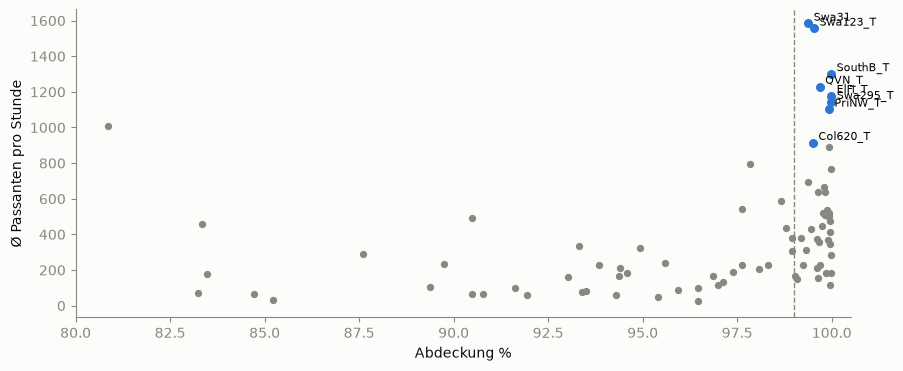

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(stats['coverage'] * 100, stats['mean'], s=18, color=MUTED)
chosen = stats.loc[stats.index.isin(make_panel(counts, select_sensors(counts)).unique_id.unique())]
ax.scatter(chosen['coverage'] * 100, chosen['mean'], s=30, color=COLORS['Chronos-Bolt'])
for name, r in chosen.iterrows():
    ax.annotate(name, (r['coverage'] * 100, r['mean']), xytext=(4, 2), textcoords='offset points', fontsize=8)
ax.axvline(99, color=MUTED, linestyle='--', linewidth=1)
ax.set(xlabel='Abdeckung %', ylabel='Ø Passanten pro Stunde', xlim=(80, 100.5));

In [4]:
panel = build_panel()
panel.groupby('unique_id').agg(stunden=('y', 'size'), imputiert=('imputed', 'sum'), mittel=('y', 'mean')).round(0)

,stunden,imputiert,mittel
unique_id,,,
Col620_T,17496,87,913.0
ElFi_T,17496,3,1178.0
PriNW_T,17496,13,1101.0
QVN_T,17496,56,1230.0
SouthB_T,17496,3,1300.0
Swa123_T,17496,82,1555.0
Swa295_T,17496,2,1144.0
Swa31,17496,109,1582.0


## Lücken

Fehlende Stunden werden aufgefüllt (kurz: Interpolation, lang: Wert der Vorwoche), damit die klassischen Verfahren lückenlose Reihen bekommen. Aufgefüllte Stunden gehen nicht in die Bewertung ein.

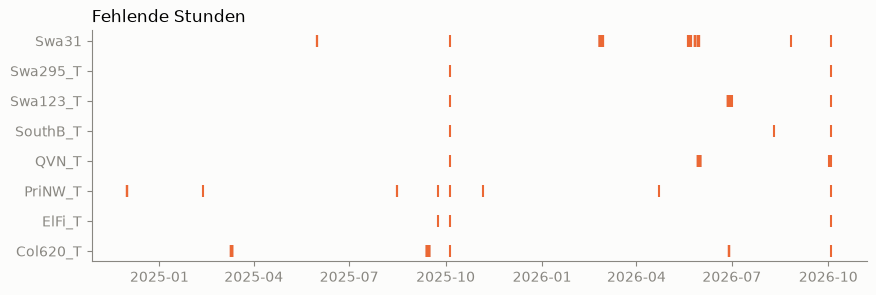

In [5]:
gaps = panel[panel.imputed]
fig, ax = plt.subplots(figsize=(10, 3))
ids = sorted(panel.unique_id.unique())
ax.scatter(gaps.ds, gaps.unique_id.map({s: i for i, s in enumerate(ids)}), marker='|', s=80, color=COLORS['LightGBM'])
ax.set_yticks(range(len(ids)), ids)
ax.set_title('Fehlende Stunden', loc='left');

## Profile

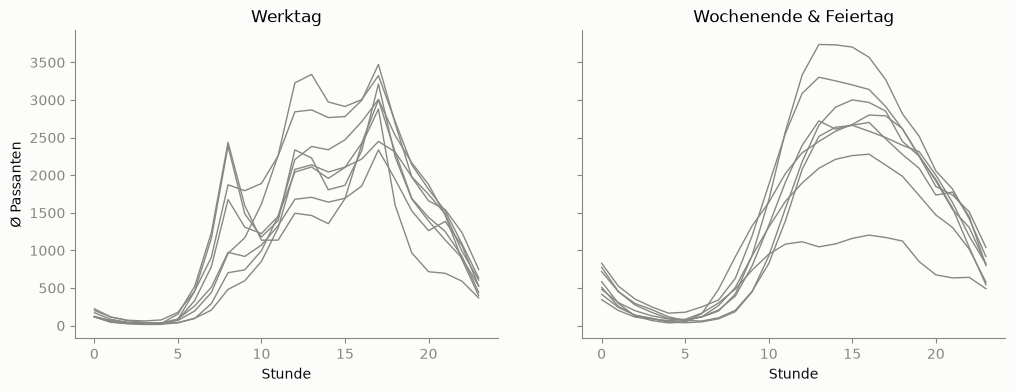

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for sensor, d in panel.groupby('unique_id'):
    axes[0].plot(d[~d.offday].groupby('hour').y.mean(), color=MUTED, linewidth=1)
    axes[1].plot(d[d.offday].groupby('hour').y.mean(), color=MUTED, linewidth=1)
axes[0].set(title='Werktag', xlabel='Stunde', ylabel='Ø Passanten')
axes[1].set(title='Wochenende & Feiertag', xlabel='Stunde');

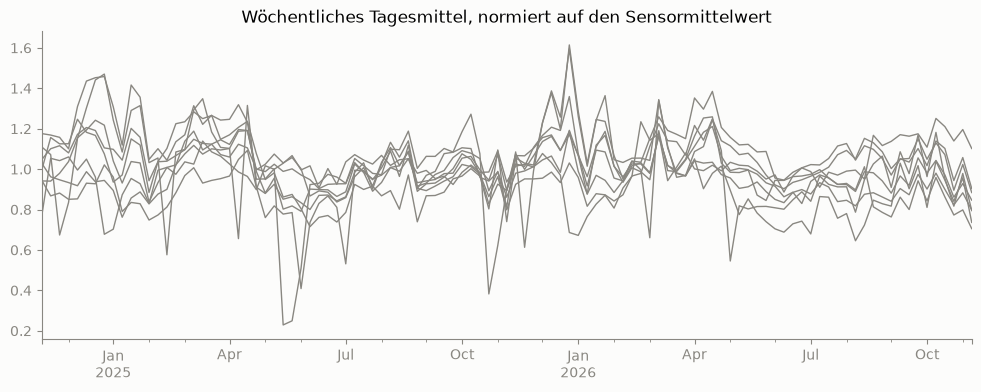

In [7]:
daily = panel.set_index('ds').groupby('unique_id').y.resample('D').sum().reset_index()
weekly = daily.groupby(['unique_id', pd.Grouper(key='ds', freq='W')]).y.mean().unstack(0)
ax = (weekly / weekly.mean()).plot(figsize=(12, 4), color=MUTED, linewidth=1, legend=False)
ax.set(title='Wöchentliches Tagesmittel, normiert auf den Sensormittelwert', xlabel='');

Deutlich sichtbar: Spitzen in der Vorweihnachtszeit, danach ein Einbruch über den Jahreswechsel. Einzelne Sensoren zeigen kurze Einbrüche (Baustellen, Sperrungen). Die Jahressaisonalität ist schwach, Feiertage und Events dominieren die Abweichungen.

## Fingerabdruck Stunde × Wochentag

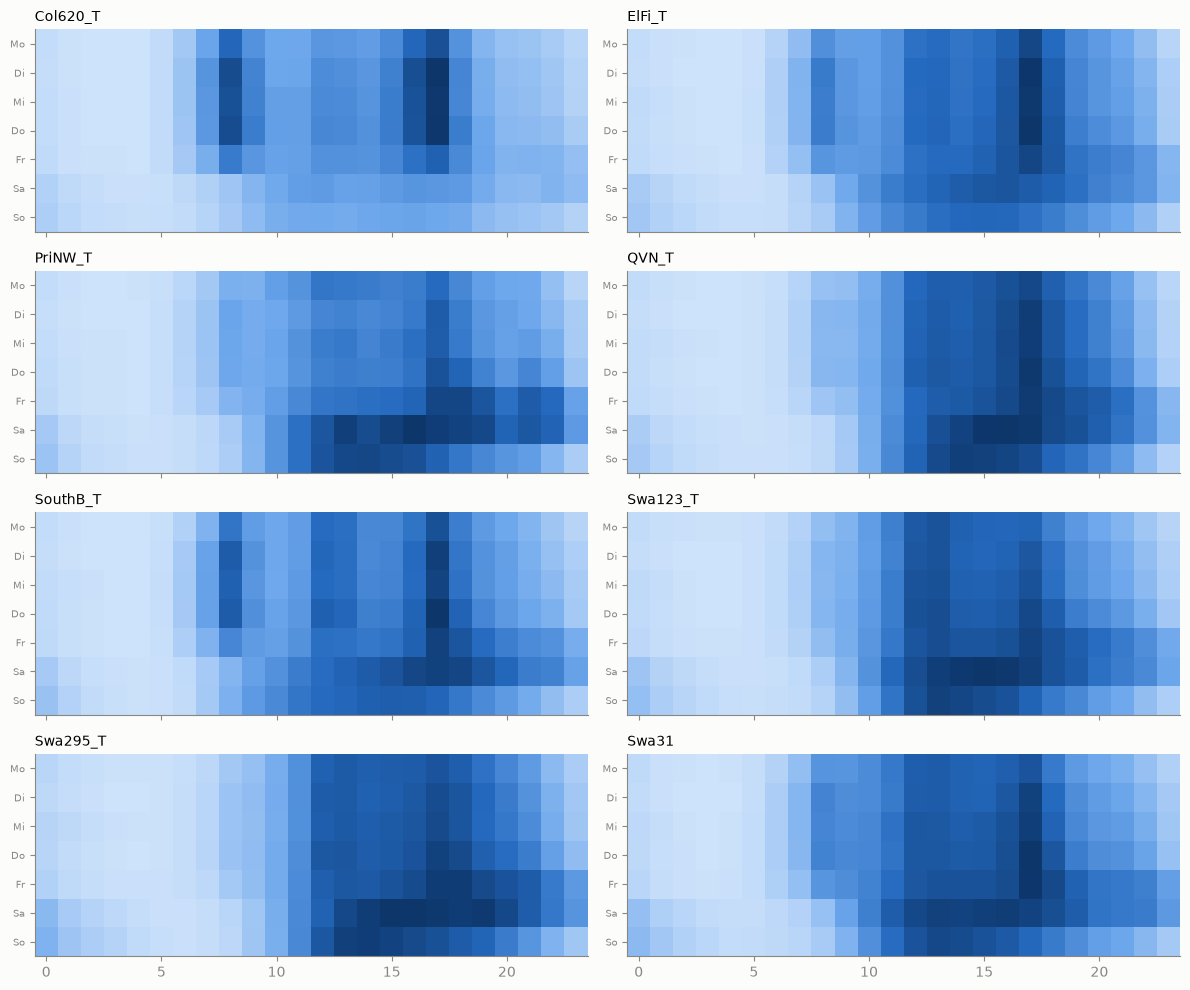

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, (sensor, d) in zip(axes.flat, panel.groupby('unique_id')):
    grid = d.groupby(['dow', 'hour']).y.mean().unstack()
    ax.imshow(grid / grid.to_numpy().max(), aspect='auto', cmap=BLUES)
    ax.set_title(sensor, loc='left', fontsize=10)
    ax.set_yticks(range(7), DAYS, fontsize=7)
fig.tight_layout()

Pendlerstandorte zeigen zwei Spitzen (8 und 17 Uhr), Einkaufs- und Ausgehlagen ein Plateau am Nachmittag und hohe Werte am Freitag- und Samstagabend.